In [1]:
### Notes

### - try aligning gaussian blobs (or 1's) without overlap to see the difference

In [2]:
### standard libraries
import time
import numpy as np
import matplotlib.pyplot as plt

### other
import mrcfile

from scipy.spatial.transform import Rotation

### my modules
from fast_volume_align_ot import utils, plots, transforms, signals, fle_3d, alignments

In [3]:
N = 95
d = 3
dx = 1
sigma = 3

f = utils.gaussian_3d(N, sigma=sigma)
g = utils.gaussian_3d(N, sigma=sigma)

f = transforms.translate_3d(f, 0, 0, 10)
g = transforms.translate_3d(g, 0, 0, 30)

In [4]:
# plt.imshow(np.sum(f, axis=0) - np.sum(g, axis=0))
# plt.axvline(N//2, linestyle='--', color='white')
# plt.axhline(N//2, linestyle='--', color='white')
# plt.show()

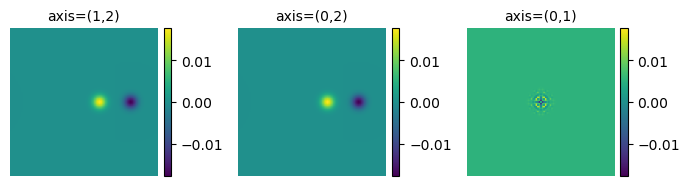

3.0103339689468036e-163 0.0023516161457126272 0.9999999999999996 0.9999999999999996


In [5]:
plots.orthogonal_2D_projection_plot(f - g)
print( np.amin(f), np.amax(f), np.sum(f), np.sum(f)*(dx**3) )

In [6]:
### Define constants

M = f.shape[0]   # grid size LxLxL
max_l = M//2

fle = fle_3d.FLEBasis3D(M, M, 1e-6, max_l=max_l, mode="complex", force_real="True")

### For Euclidean distance
h = 1/np.floor( (N+1+N%2)/2 )
dV = h**3

### For sliced Wasserstein distance
# z = np.linspace(-1, 1, N, endpoint=False)
z = np.linspace(0, 1, N, endpoint=False)
phis = np.linspace(0, 2*np.pi, N, endpoint=False)
thetas = np.linspace(0, np.pi, N, endpoint=True)
sinthetas = np.sin(thetas)[np.newaxis, np.newaxis, :]
dVsphere = (z[1]-z[0])*(thetas[1]-thetas[0])*(phis[1]-phis[0]) 

print(dV)
print(dVsphere)

9.042245370370368e-06
2.3267765429573544e-05


In [7]:
### Compute transforms

f_t = transforms.Transform(f, d=3).inverse_cdf_transform()[0]
f_tp, f_tn = transforms.Transform(f, d=3, apply_ramp=True).signed_inverse_cdf_transform()

f_norm = np.sqrt(np.sum(f**2))
f_t_norm = np.sqrt(np.sum(f_t**2 * sinthetas))
f_tp_norm = np.sqrt(np.sum(f_tp[0]**2 * sinthetas))
f_tn_norm = np.sqrt(np.sum(f_tn[0]**2 * sinthetas))


g_t = transforms.Transform(g, d=3).inverse_cdf_transform()[0]
g_tp, g_tn = transforms.Transform(g, d=3, apply_ramp=True).signed_inverse_cdf_transform()

g_norm = np.sqrt(np.sum(g**2))
g_t_norm = np.sqrt(np.sum(g_t**2 * sinthetas))
g_tp_norm = np.sqrt(np.sum(g_tp[0]**2 * sinthetas))
g_tn_norm = np.sqrt(np.sum(g_tn[0]**2 * sinthetas))

In [8]:
### Euclidean distance
t = time.time()
c_l2, R_idx = alignments.align_l2(np.flip(f, axis=2), np.flip(g, axis=2), fle)
dists_l2 = (f_norm**2 + g_norm**2) * dV - 2*c_l2
print(R_idx)
print("  L2: ", time.time() - t)
print('\n')

### sliced 2-Wasserstein distance
t = time.time()
c_sw, R_idx = alignments.fast_rotational_correlation(f_t, g_t, fle)
dists_sw = ((f_t_norm**2 + g_t_norm**2) * dVsphere - 2*c_sw) / (4*np.pi)
print(R_idx)
print("  SW: ", time.time() - t)
print('\n')


### ramp-filtered sliced 2-Wasserstein distance
t = time.time()
cp, R_idx = alignments.fast_rotational_correlation(f_tp[0], g_tp[0], fle)
cn, R_idx = alignments.fast_rotational_correlation(f_tn[0], g_tn[0], fle)
d_rfsw_p = ((f_tp_norm**2 + g_tp_norm**2) * dVsphere - 2*cp) / (4*np.pi)
d_rfsw_n = ((f_tn_norm**2 + g_tn_norm**2) * dVsphere - 2*cn) / (4*np.pi)
dists_rfsw = (d_rfsw_p + d_rfsw_n) / 2
print(R_idx)
print("RFSW: ", time.time() - t)

correlation R=0:  1.1235786211226779e-13
all correlation:  1.1064990758412602e-14
0
  L2:  28.382091999053955


correlation R=0:  3.3076757294027503
all correlation:  3.1676016731856222
0
  SW:  17.837085008621216


correlation R=0:  3.2969519963080947
all correlation:  3.156849952152867
correlation R=0:  3.6273988573210154
all correlation:  3.5346402831008885
0
RFSW:  35.61984395980835


In [9]:
phi_idx = 0

d_l2 = dists_l2[phi_idx, :, :]
d_sw = dists_sw[phi_idx, :, :]
d_rfsw = dists_rfsw[phi_idx, :, :]

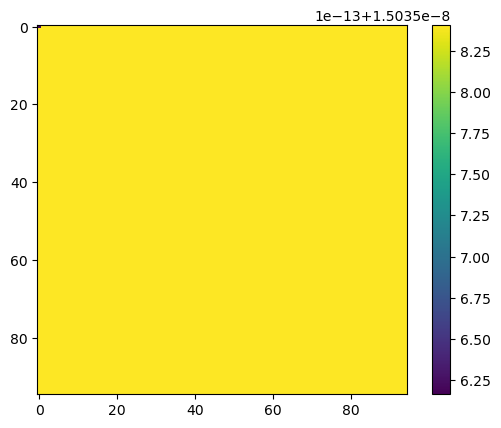

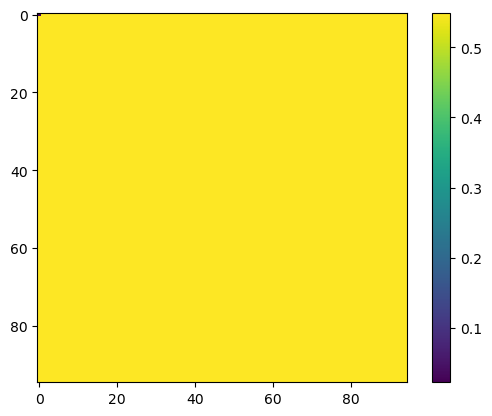

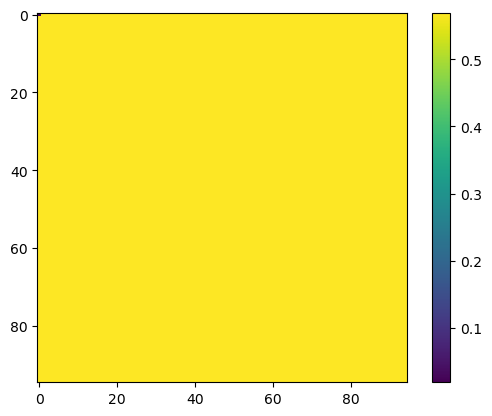

In [10]:
plt.imshow(d_l2)
plt.colorbar()
plt.show()

plt.imshow(d_sw)
plt.colorbar()
plt.show()

plt.imshow(d_rfsw)
plt.colorbar()
plt.show()

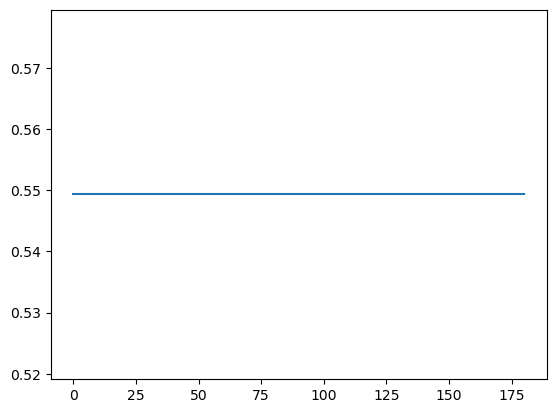

In [11]:
plt.plot(np.rad2deg(thetas), d_sw[:, N//2])

In [12]:
np.sum(f * g) * dV

1.123578665714501e-13

In [13]:
np.amax(c_l2)

1.1235786211226779e-13

In [14]:
np.sum(f_t * g_t) * dVsphere

5.446253259886161

In [15]:
np.amax(c_sw)

3.3076757294027503

In [16]:
### now I want to check
### how far the zero rotation correlation value is
### from the correlation returned from the fast_rot_corr

In [17]:
a = np.sum((f_t - g_t)**2 * sinthetas) * dVsphere 
b = (np.sum(f_t**2 * sinthetas) + np.sum(g_t**2 * sinthetas) - 2*np.sum(f_t * g_t * sinthetas)) * dVsphere